# Neuron Migration - Rules of t3 (surrender value) and t4 (annual statement)

Both tasks rest on the same fund accounting: every unit booking of every policy. The new system has to calculate
the premium and charge bookings itself, so `accounting.py` generates them from the premiums, the parameters and the
market data; only the customer orders (switches, withdrawals, surrenders, death benefits) are taken from the export.

The rules were found booking by booking with **teacher forcing**: the holdings before each booking come from the
target units of the earlier bookings (`research/t3_calibrate.py`), so every formula can be checked on its own. The
cases where a formula failed were inspected one by one, and every fix is a rule below.

# Import libraries

In [1]:
import sys
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from decimal import Decimal

sys.path.insert(0, '..')
sys.path.insert(0, '../../../research')
sys.path.insert(0, '../..')
from legacy_loader import LegacyData
from accounting import all_bookings
from surrender import surrender_values
from statement import annual_statements
import t3_engine_check
import scoring

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

# Hyperparameters

In [2]:
project_folder = pathlib.Path('../../..').resolve()

targets_dir = project_folder / 'targets'

cache_dir = project_folder / '.cache'

conversion = pd.Timestamp('2007-08-11')

sample_size = 150

In [3]:
data = LegacyData(project_folder / 'legacy', cache_dir=cache_dir)
target_bookings = pd.read_csv(targets_dir / 't3_booking.csv').set_index('booking_id')
legacy_bookings = data.table('NRBOOK')

# The monthly charges

## Which units a charge sees

The charge run of a day runs at 01:30, before the trades of that day. Policy `BL10000800` bought units on
1995-07-31, the same day as its monthly charge: the management charge (2.74 for fund N0013) only fits the units held
**before** that purchase.

In [4]:
policy = legacy_bookings[(legacy_bookings.BK_POLNR == 'BL10000800') & (legacy_bookings.BK_FNDID == 'N0013')]
policy = policy[policy.BK_TRDDT.between('1995-06-25', '1995-08-05')].copy()
policy['amount'] = policy.BK_BOOKID.map(target_bookings.amount_pc)
policy['units'] = policy.BK_BOOKID.map(target_bookings.units)
policy[['BK_EVTNR', 'BK_BKTYP', 'BK_TRDDT', 'BK_PRCDT', 'amount', 'units']]

,BK_EVTNR,BK_BKTYP,BK_TRDDT,BK_PRCDT,amount,units
1127514,17,ADM,1995-06-30,1995-06-30,2.89,-0.009628
1127515,17,AMC,1995-06-30,1995-06-30,2.37,-0.007896
1127516,17,RSK,1995-06-30,1995-06-30,1.49,-0.004964
1127521,18,PRM,1995-07-03,1995-07-03,115.20,0.379447
1127524,19,PRM,1995-07-31,1995-07-31,115.20,0.382581
1127529,20,ADM,1995-07-31,1995-07-31,2.88,-0.009564
1127530,20,AMC,1995-07-31,1995-07-31,2.74,-0.009099
1127531,20,RSK,1995-07-31,1995-07-31,1.47,-0.004881


## COBOL charged the management fee by the day

In the COBOL era (before the conversion on 2007-08-11) the management charge is not rate / 12: the implied factor
follows the length of the month, `days / 360` (Actual/360). Neuron NG charges rate / 12.

In [5]:
amc = legacy_bookings[(legacy_bookings.BK_BKTYP == 'AMC') & (legacy_bookings.BK_POLNR == 'BL10000003')].head(13).copy()
amc['amount'] = amc.BK_BOOKID.map(target_bookings.amount_pc)
amc['days since last charge'] = amc.BK_TRDDT.diff().dt.days
amc[['BK_TRDDT', 'amount', 'days since last charge']]

,BK_TRDDT,amount,days since last charge
4321,1997-03-01,0.89,NaN
4325,1997-04-01,1.90,31.0
4329,1997-05-01,2.67,30.0
4333,1997-06-01,3.72,31.0
4337,1997-07-01,4.61,30.0
4341,1997-08-01,5.98,31.0
4345,1997-09-01,7.78,31.0
4349,1997-10-01,8.29,30.0
4353,1997-11-01,8.64,31.0
4357,1997-12-01,8.85,30.0


## Technical corrections do not count

Event 21 of `BL10000004` is a technical correction (990) with a switch-in booking. The next management charge only
fits the holding without it, so the bookings of technical corrections (and of reversed events, 900) are ignored.

In [6]:
events = data.table('NREVNT')
events[(events.EV_POLNR == 'BL10000004') & events.EV_EVTNR.between(19, 23)][['EV_EVTNR', 'EV_EVTTP', 'EV_EFFDT', 'EV_USRID']]

,EV_EVTNR,EV_EVTTP,EV_EFFDT,EV_USRID
685,19,300,2018-06-01,NGBATCH
686,20,300,2018-07-01,NGBATCH
687,21,990,2018-07-21,U136
688,22,300,2018-08-01,NGBATCH
689,23,300,2018-09-01,NGBATCH


## Splitting a charge over the funds and pots

The admin fee and the risk charge are split in proportion to the value of each fund and pot. The shares are rounded,
and the largest position takes the rounding difference: on 2017-09-01 policy `BL10000013` pays 4.45 + 0.51 + 1.54,
where the plain rounding gives 4.44.

In [7]:
split = legacy_bookings[(legacy_bookings.BK_POLNR == 'BL10000013') & (legacy_bookings.BK_TRDDT == '2017-09-01')].copy()
split['amount'] = split.BK_BOOKID.map(target_bookings.amount_pc)
split[['BK_FNDID', 'BK_POTCD', 'BK_BKTYP', 'BK_PRCDT', 'amount']]

,BK_FNDID,BK_POTCD,BK_BKTYP,BK_PRCDT,amount
12699,N0002,1,ADM,2017-09-01,4.45
12700,N0002,1,AMC,2017-09-01,5.20
12701,N0002,1,RSK,2017-09-01,2.87
12702,N0002,2,ADM,2017-09-01,0.51
12703,N0002,2,AMC,2017-09-01,0.24
12704,N0002,2,RSK,2017-09-01,0.33
12705,N0008,1,ADM,2017-09-01,1.54
12706,N0008,1,AMC,2017-09-01,1.80
12707,N0008,1,RSK,2017-09-01,1.00


# The premium bookings

Each fund buys on its own: on the first day after the money date that **the fund** has a price. When one fund has no
price on the next business day, only that fund trades later. This explains every premium traded two days late.

In [8]:
premiums = legacy_bookings[legacy_bookings.BK_BKTYP == 'PRM']
prices = data.table('NRFPRC')
price_days = {fund: sorted(rows.FP_PRCDT) for fund, rows in prices.groupby('FP_FNDID')}
sample = premiums.sample(20000, random_state=1)
first_price_day = [next(day for day in price_days[fund] if day > money) for fund, money in zip(sample.BK_FNDID, sample.BK_RCVDT)]
print('trade date = first price day of the fund after the money date:', (pd.Series(first_price_day, index=sample.index) == sample.BK_TRDDT).mean())

trade date = first price day of the fund after the money date: 1.0


# Exchange rates

- The export has a few rates with lowercase currency codes (`chf`, `eur`, ...). They fill days without an uppercase
  rate, so they are read as uppercase.
- Charges and valuations convert with the rate of their day; premiums with the rate of the day **before** the trade
  day (the day the money was converted). Rates are not rounded.

In [9]:
rates = data.table('NRFXRT')
rates[rates.FX_CCY.str.islower()].FX_CCY.value_counts()

FX_CCY
sek    23
chf    17
usd    17
gbp    14
eur     9
Name: count, dtype: int64

# Check: all bookings of a sample of policies

The engine runs on a random sample of train policies and every premium, admin, management and risk booking is
compared with the export and the target amounts and units.

In [10]:
sample_data, chosen = t3_engine_check.sample_data(sample_size)
bookings = all_bookings(sample_data, pd.Timestamp('2026-06-30').date())
compared = t3_engine_check.compare(bookings, sample_data)
print(len(bookings), 'bookings calculated')
pd.crosstab(compared.type, compared.ok, colnames=['exact'])

286758 bookings calculated


exact,True
type,
ADM,103932
AMC,104542
PRM,20844
RSK,56395


On all 3,019 train policies, 5,024,847 bookings: all exact except three risk bookings of `BL10004387` on 2020-12-01, which are 3.19 times the calculated ones (a manual correction, see t5).

# t3 Surrender value

The units are valued at the bid price on or before the valuation date, converted and rounded to the cent per fund and
pot (truncated in the COBOL era). The penalty comes from the surrender scale of the product and the completed policy
years, with no penalty in the waiver periods (financial crisis 2008, COVID 2020). COBOL truncated the surrender value
`value x (1 - rate)`.

In [11]:
targets_t3 = scoring.read_targets(targets_dir, 't3_surrender_value')
calculated = scoring.normalize('t3_surrender_value', surrender_values(data, scoring.arguments('t3_surrender_value', targets_t3)[0]))
wrong = [(key[0], key[1], float(targets_t3[key]), float(calculated[key])) for key in targets_t3 if calculated.get(key) != targets_t3[key]]
print(f'{len(targets_t3) - len(wrong)} of {len(targets_t3)} exact')
wrong = pd.DataFrame(wrong, columns=['policy', 'valuation date', 'target', 'calculated'])
wrong['difference'] = wrong.target - wrong.calculated
wrong

6137 of 6153 exact


,policy,valuation date,target,calculated,difference
0,BL10000321,2025-12-31,82224.81,82049.81,175.0
1,BL10000694,2025-12-31,103820.37,103462.37,358.0
2,BL10000768,2020-04-30,8179.73,8062.73,117.0
3,BL10001063,2020-04-30,23620.49,23586.49,34.0
4,BL10001080,2020-04-30,6929.07,6771.07,158.0
5,BL10001756,2025-12-31,17778.65,17563.65,215.0
6,BL10001820,2025-12-31,13512.66,13284.66,228.0
7,BL10001897,2020-04-30,65417.75,65303.75,114.0
8,BL10002328,2020-04-30,2215.85,1716.85,499.0
9,BL10002704,2025-12-31,20138.77,20123.77,15.0


All 16 differences are whole francs while the policy value (diagnostic column) is exact: manual corrections.

# t4 Annual statement

The statement sums the bookings by calendar year: premiums by money date, entry charges (premium share less the
amount invested) and the monthly charges by trade date.

In [12]:
targets_t4 = scoring.read_targets(targets_dir, 't4_annual_statement')
calculated = scoring.normalize('t4_annual_statement', annual_statements(data))
columns = ['premiums', 'entry', 'admin', 'management', 'risk', 'total']
wrong = [(key[0], key[1]) + tuple(float(t) - float(c) for t, c in zip(targets_t4[key], calculated[key]))
         for key in targets_t4 if calculated.get(key) != targets_t4[key]]
print(f'{len(targets_t4) - len(wrong)} of {len(targets_t4)} exact')
listed = set(data.table('NREXCP').query("EX_TARGET.str.startswith('t4')", engine='python').EX_POLNR)
wrong = pd.DataFrame(wrong, columns=['policy', 'year'] + columns)
wrong['listed in NREXCP'] = wrong.policy.isin(listed)
wrong

34124 of 34145 exact


,policy,year,premiums,entry,admin,management,risk,total,listed in NREXCP
0,BL10000099,2001,0.0,0.0,147.0,0.0,0.00,147.00,True
1,BL10000139,2014,0.0,0.0,136.0,0.0,0.00,136.00,True
2,BL10000151,2015,0.0,0.0,123.0,0.0,0.00,123.00,True
3,BL10000182,2014,0.0,0.0,45.0,0.0,0.00,45.00,True
4,BL10000595,2024,0.0,0.0,30.0,0.0,0.00,30.00,True
5,BL10002682,2004,0.0,0.0,48.0,0.0,0.00,48.00,True
6,BL10002708,2013,0.0,0.0,132.0,0.0,0.00,132.00,True
7,BL10003181,2018,0.0,0.0,121.0,0.0,0.00,121.00,True
8,BL10003208,2010,0.0,0.0,115.0,0.0,0.00,115.00,True
9,BL10003421,2023,0.0,0.0,7.0,0.0,0.00,7.00,True


20 admin fees differ by whole francs (16 listed in `NREXCP`) and one risk charge is the manual correction of `BL10004387`: every difference is a manual correction.

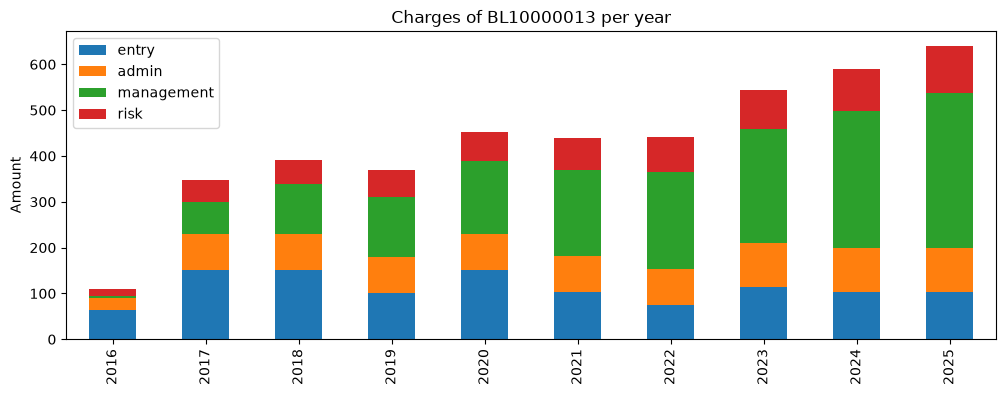

In [13]:
example = pd.DataFrame([calculated[('BL10000013', year)] for year in range(2016, 2026)], index=range(2016, 2026),
                       columns=columns).astype(float)
example[['entry', 'admin', 'management', 'risk']].plot.bar(stacked=True, figsize=(12, 4), title='Charges of BL10000013 per year')
plt.ylabel('Amount')
plt.show()

# Summary

| Booking | Rule |
|---|---|
| Premium (PRM) | per fund: received x allocation x (1 - entry charge), all on the money date; pot 1 within `PD_INIMON` months; units at the ask price of the fund's first price day after the money date, FX of the day before |
| Admin fee (ADM) | fee valid on the anniversary (capped at the value), split by value |
| Management (AMC) | value x pot rate (or agreement) / 12; COBOL: x days / 360 |
| Risk (RSK) | sum at risk on the value after admin and management charge, split by the value left |
| All | positions valued at bid with the FX of the day; the rounding difference goes to the largest position; no booking for 0.00; COBOL truncates, Neuron NG rounds half up |
| Ignored | reversed events (900), technical corrections (990), charges from the day of surrender or death |